## Week 7 – Dimensionality Reduction

 Credit Card Fraud Detection Dataset

 Course: 24ADI204 – Data Science and Visualization

 Participants:
*Abishake P 25BAD002

*ArunVignesh R S 25BAD012

*Nishanth M 25BAD069



## Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

print("Libraries imported successfully!")

Libraries imported successfully!


## Upload the dataset

In [2]:
uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Saving creditcard_cleaned.csv to creditcard_cleaned.csv
Dataset loaded successfully!
Dataset shape: (283726, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## Check and clean the target column

In [3]:
print("Missing values in Class:", df["Class"].isnull().sum())

df = df.dropna(subset=["Class"]).copy()
df["Class"] = pd.to_numeric(df["Class"], errors="coerce")
df = df.dropna(subset=["Class"])
df = df[df["Class"].isin([0, 1])].copy()
df["Class"] = df["Class"].astype(int)

print("Updated dataset shape:", df.shape)
print(df["Class"].value_counts())

Missing values in Class: 0
Updated dataset shape: (283726, 31)
Class
0    283253
1       473
Name: count, dtype: int64


## Separate features and target

In [4]:
y = df["Class"]

X = df.drop(columns=["Class"])
X = X.select_dtypes(include=[np.number])

X = X.replace([np.inf, -np.inf], np.nan)
X = X.dropna(axis=1, how="all")

constant_cols = [
    col for col in X.columns
    if X[col].nunique(dropna=True) <= 1
]

X = X.drop(columns=constant_cols)

print("Number of input features:", X.shape[1])
print("Target variable:", y.name)

Number of input features: 30
Target variable: Class


##Split into training and testing data

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (226980, 30)
Testing data: (56746, 30)


## Handle missing values

In [6]:
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)

X_test_imputed = imputer.transform(X_test)

print("Missing values handled successfully!")
print("Training shape:", X_train_imputed.shape)
print("Testing shape:", X_test_imputed.shape)

Missing values handled successfully!
Training shape: (226980, 30)
Testing shape: (56746, 30)


In [9]:
from sklearn.feature_selection import VarianceThreshold

## Apply Variance Thresholding

In [10]:
vt = VarianceThreshold(threshold=0.01)

X_train_variance = vt.fit_transform(X_train_imputed)

X_test_variance = vt.transform(X_test_imputed)

selected_columns = X_train.columns[vt.get_support()]

print("Features before Variance Thresholding:", X_train.shape[1])

print("Features after Variance Thresholding:", len(selected_columns))

print("Selected features:")
print(list(selected_columns))

Features before Variance Thresholding: 30
Features after Variance Thresholding: 30
Selected features:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']


## Visualize Feature Variance

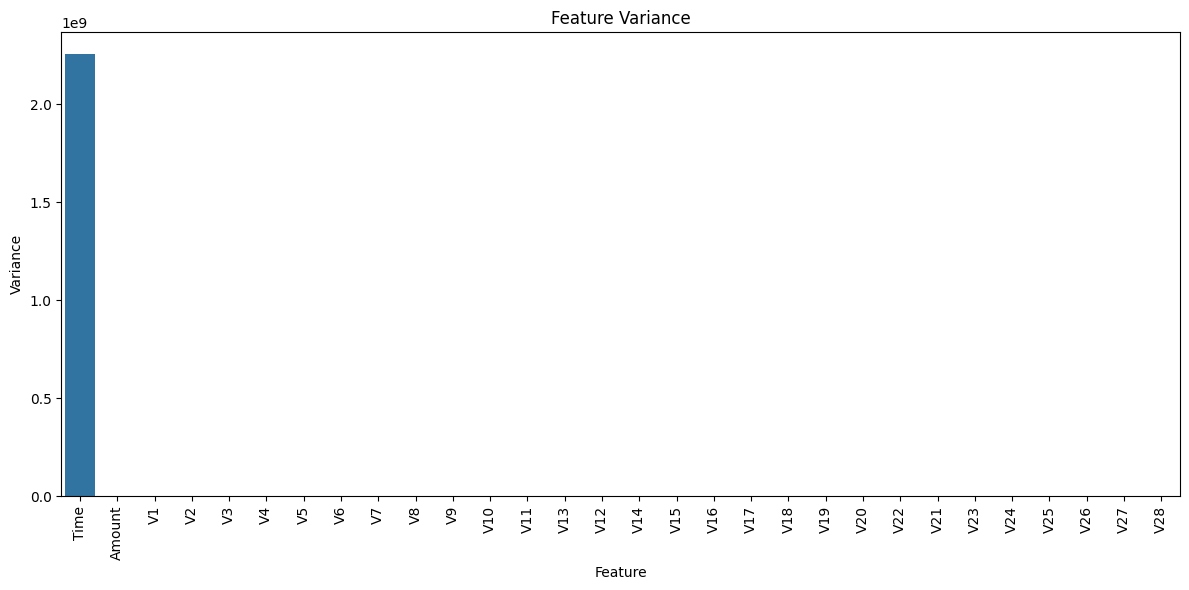

In [11]:
variance_values = vt.variances_

variance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Variance": variance_values
})

variance_df = variance_df.sort_values(
    by="Variance",
    ascending=False
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=variance_df,
    x="Feature",
    y="Variance"
)

plt.xticks(rotation=90)
plt.title("Feature Variance")
plt.tight_layout()
plt.show()

## Apply SelectKBest Using Mutual Information

In [13]:
k = min(10, X_train_variance.shape[1])

selector = SelectKBest(
    score_func=lambda X, y: mutual_info_classif(
        X, y, random_state=42
    ),
    k=k
)

X_train_selected = selector.fit_transform(
    X_train_variance, y_train
)

X_test_selected = selector.transform(X_test_variance)

selected_features = selected_columns[selector.get_support()]

print("Top selected features:")
print(list(selected_features))

print("Number of selected features:", len(selected_features))

Top selected features:
['V3', 'V4', 'V9', 'V10', 'V11', 'V12', 'V14', 'V16', 'V17', 'V18']
Number of selected features: 10


## Visualize Selected Features

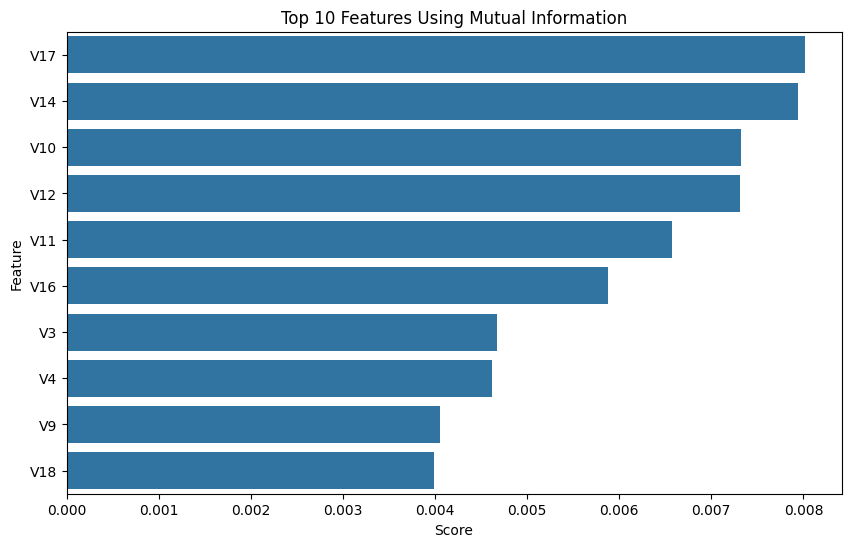

In [14]:
feature_scores = pd.DataFrame({
    "Feature": selected_columns,
    "Score": selector.scores_
})

feature_scores = feature_scores.sort_values(
    by="Score",
    ascending=False
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_scores.head(10),
    x="Score",
    y="Feature"
)

plt.title("Top 10 Features Using Mutual Information")
plt.show()

## Apply Standard Scaling for PCA

In [15]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_variance)

X_test_scaled = scaler.transform(X_test_variance)

print("Standard scaling completed!")

Standard scaling completed!


## Apply PCA

In [16]:
pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train_scaled)

X_test_pca = pca.transform(X_test_scaled)

print("Original number of features:", X_train_variance.shape[1])

print("Number of PCA components:", X_train_pca.shape[1])

print("Total explained variance:",
      sum(pca.explained_variance_ratio_))

Original number of features: 30
Number of PCA components: 27
Total explained variance: 0.9580017279502765


## Visualize Explained Variance

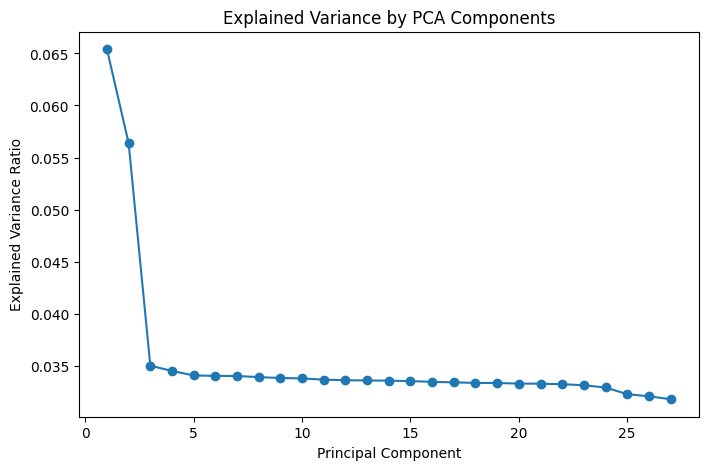

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(pca.explained_variance_ratio_) + 1),
    pca.explained_variance_ratio_,
    marker="o"
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("Explained Variance by PCA Components")

plt.show()

## Visualize Cumulative Explained Variance

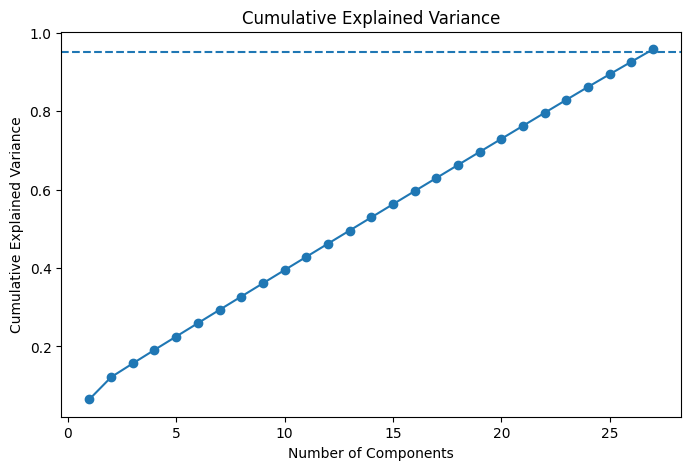

In [18]:
cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
)

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(y=0.95, linestyle="--")

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance")

plt.show()

## Compare Feature Reduction

In [19]:
print("Original input features:", X_train.shape[1])

print("After Variance Thresholding:", X_train_variance.shape[1])

print("After SelectKBest:", X_train_selected.shape[1])

print("After PCA:", X_train_pca.shape[1])

Original input features: 30
After Variance Thresholding: 30
After SelectKBest: 10
After PCA: 27


## Save the Results

In [20]:
# Save feature variance information
variance_df.to_csv(
    "week7_variance_scores.csv",
    index=False
)

# Save Mutual Information scores
feature_scores.to_csv(
    "week7_feature_scores.csv",
    index=False
)

# Save selected feature datasets
selected_train_df = pd.DataFrame(
    X_train_selected,
    columns=selected_features
)

selected_train_df["Class"] = y_train.reset_index(drop=True)

selected_test_df = pd.DataFrame(
    X_test_selected,
    columns=selected_features
)

selected_test_df["Class"] = y_test.reset_index(drop=True)

selected_train_df.to_csv(
    "week7_selected_train.csv",
    index=False
)

selected_test_df.to_csv(
    "week7_selected_test.csv",
    index=False
)

# Save PCA datasets
pca_train_df = pd.DataFrame(X_train_pca)

pca_train_df["Class"] = y_train.reset_index(drop=True)

pca_test_df = pd.DataFrame(X_test_pca)

pca_test_df["Class"] = y_test.reset_index(drop=True)

pca_train_df.to_csv(
    "week7_pca_train.csv",
    index=False
)

pca_test_df.to_csv(
    "week7_pca_test.csv",
    index=False
)

print("All Week 7 files saved successfully!")

All Week 7 files saved successfully!


##  Final Week 7 summary

In [22]:
print("WEEK 7 – FINAL SUMMARY")
print("=" * 35)
print("Rows used:", len(df))
print("Original numeric input features:", X_train.shape[1])
print("Features after Variance Thresholding:", X_train_variance.shape[1])
print("Features selected by Mutual Information:", X_train_selected.shape[1])
print("Selected feature names:", selected_features)
print("PCA components retained:", X_train_pca.shape[1])
print("PCA variance retained:", round(pca.explained_variance_ratio_.sum() * 100, 2), "%")
print("Training rows:", len(y_train))
print("Testing rows:", len(y_test))
print("Week 7 processing completed successfully!")

WEEK 7 – FINAL SUMMARY
Rows used: 283726
Original numeric input features: 30
Features after Variance Thresholding: 30
Features selected by Mutual Information: 10
Selected feature names: Index(['V3', 'V4', 'V9', 'V10', 'V11', 'V12', 'V14', 'V16', 'V17', 'V18'], dtype='object')
PCA components retained: 27
PCA variance retained: 95.8 %
Training rows: 226980
Testing rows: 56746
Week 7 processing completed successfully!
